# Ajusta cinco modelos cinéticos y compara la proyección del banco

**Pregunta:** ¿Qué formas cinéticas ajustadas conservan la respuesta batch y la proyección del banco en este caso de autoría propia?

Nivel: 2. Requisitos previos: Nivel 1: Interpreta un banco de flotación como respuesta cinética. Tiempo de lectura: 30 minutos.

## Objetivos

Ejecuta los ajustes no lineales acotados de OreFlow, inspecciona límites y residuales, y compara la predicción de banco con la referencia exacta de tasas distribuidas del motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 2 sobre 02-flotation, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; escenario nominal Cu-Mo y registro cinético generado en `data/derived/cases/copper_molybdenum.json`, licencia MIT del proyecto. La respuesta es simulada, no medida en planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Los datos batch virtuales mezclan respuestas de primer orden por clase de partícula. OreFlow ajusta formas de primer orden, Kelsall, Klimpel, gamma y exponencial estirada con Levenberg–Marquardt acotado. Luego proyecta cada modelo a un banco; `kinetic_record` es la entrada de producción. Ajuste y proyección son verificaciones diferentes.

Llama al ajustador de producción en un caso resuelto. Esto ejecuta las cinco implementaciones de modelos OreFlow.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.kinetics import kinetic_record

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == "copper_molybdenum")
result = simulate(case.ore, case.plant, case.nominal)
fits = kinetic_record(
    result.flotation, result.ore, case.nominal.rougher_cells, result.metrics["rougher_recovery_pct"]
)
print("status:", fits["status"], "| fitted models:", len(fits.get("models", [])))


status: computed | fitted models: 5


Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un óptimo interior.

In [3]:
# Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un
# óptimo interior.
summary = pd.DataFrame(
    [
        {
            "model": m["id"],
            "RMSE (puntos)": m["rmse_pct"],
            "converged": m["converged"],
            "at bound": ", ".join(m["at_bound"]) or "no",
        }
        for m in fits["models"]
    ]
)
display(summary.set_index("model").round(4))


,RMSE (puntos),converged,at bound
model,,,
first_order,1.6397,True,no
kelsall,0.0283,True,no
klimpel,0.3976,True,no
gamma,0.1464,True,no
stretched_exponential,0.6667,True,no


Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.

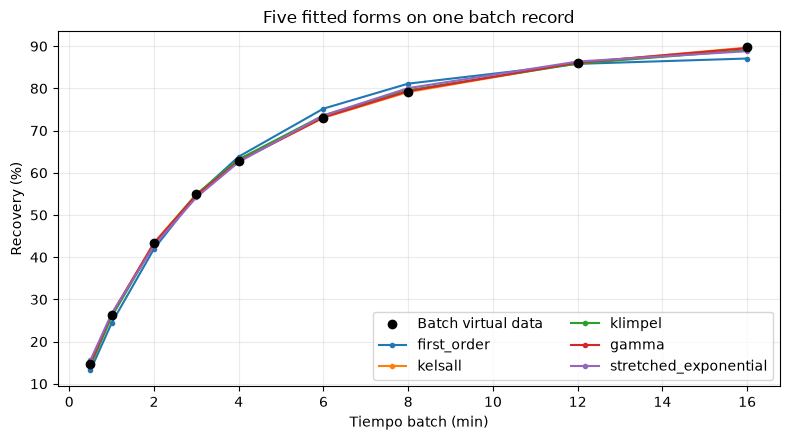

In [4]:
# Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(
    fits["times_min"],
    fits["batch_recovery_pct"],
    color="black",
    zorder=4,
    label="Batch virtual data",
)
for model in fits["models"]:
    ax.plot(fits["times_min"], model["fitted_pct"], marker=".", label=model["id"])
ax.set(
    xlabel="Tiempo batch (min)",
    ylabel="Recovery (%)",
    title="Five fitted forms on one batch record",
)
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()


La figura 13 de nivel 2 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 13 de nivel 2 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 13 de nivel 2 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 13 solo guía la comparación.

Compara las proyecciones agregadas del banco con el cálculo exacto de tasas distribuidas, incluso después de la última muestra batch.

In [5]:
# Compara las proyecciones agregadas del banco con el cálculo exacto de tasas distribuidas, incluso
# después de la última muestra batch.
projection = pd.DataFrame(
    [
        {
            "model": m["id"],
            "bank projection (%)": m["bank_projection_pct"],
            "error vs exact (points)": m["lumping_error_pct"],
            "ultimate gap (points)": m["ultimate_gap_pct"],
        }
        for m in fits["models"]
    ]
)
display(projection.round(3))
print("exact bank recuperación (%):", fits["bank"]["exact_true_flotation_pct"])


,model,bank projection (%),error vs exact (points),ultimate gap (points)
0,first_order,87.393,-6.590,0.471
1,kelsall,92.662,-1.320,4.540
2,klimpel,92.665,-1.318,9.604
3,gamma,92.951,-1.032,7.034
4,stretched_exponential,90.005,-3.977,1.724


exact bank recuperación (%): 93.9822410776771


En el caso de nivel 2 sobre 02 flotation, la corrida con 0.8× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 02 flotation, con 0.8× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 512.0
recovery (%): 94.842
product P80 (µm): 150.0


En el caso de nivel 2 sobre 02 flotation, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 02 flotation, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


En el caso de nivel 2 sobre 02 flotation, la corrida con 1.0× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 02 flotation, con 1.0× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 640.0
recovery (%): 93.447
product P80 (µm): 150.0


En el caso de nivel 2 sobre 02 flotation, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 02 flotation, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


En el caso de nivel 2 sobre 02 flotation, la corrida con 1.2× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 02 flotation, con 1.2× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 768.0
recovery (%): 89.749
product P80 (µm): 167.43


En la lección de nivel 2 sobre 02 flotation, la lectura del gráfico 1 considera en esta figura del nivel 2 sobre 02 flotation, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 2 sobre 02 flotation, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 2 sobre 02 flotation, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 2 sobre 02 flotation, la lectura del gráfico 4 considera en «Ajusta cinco modelos cinéticos y compara la proyección del banco», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

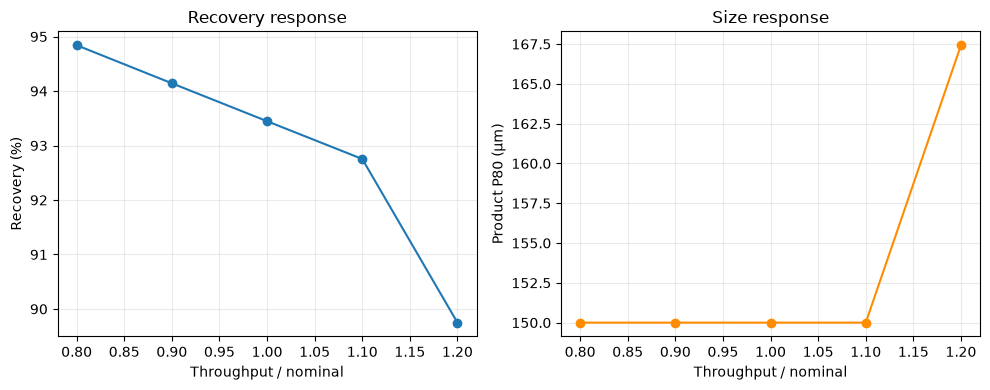

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 27 de nivel 2 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 27 de nivel 2 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 27 de nivel 2 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 27 solo guía la comparación.

En el nivel 2 de 02 flotation, la interpretación 1 es que la recuperación por flotación depende de los sólidos y minerales que entrega la molienda, los parámetros declarados de flotabilidad, la respuesta al colector y el tiempo de residencia disponible. En el nivel 2 de 02 flotation, la interpretación 2 es que un mayor tratamiento reduce el tiempo disponible por unidad de masa si el volumen de celdas no cambia. En el nivel 2 de 02 flotation, la interpretación 3 es que el modelo representa ese acoplamiento en el cálculo del banco. En el nivel 2 de 02 flotation, la interpretación 4 es que no anima partículas individuales ni infiere comportamiento de espuma desde una imagen. En el nivel 2 de 02 flotation, la interpretación 5 es que compara recuperación del mineral valioso con ley de concentrado y recuperación de agua, porque una mejora de recuperación también puede arrastrar más ganga o agua. En el nivel 2 de 02 flotation, la interpretación 6 es que formas cinéticas de primer orden, fracción rápida/lenta y tasas distribuidas pueden ajustar curvas batch similares y producir proyecciones distintas del banco. En el nivel 2 de 02 flotation, la interpretación 7 es que una referencia sintética de tasas exactas permite medir error de aproximación interno, pero no es un ensayo de laboratorio. En el nivel 2 de 02 flotation, la interpretación 8 es que transferir a una planta requiere muestras temporizadas, registros de reactivos, aire, geometría de celdas y una campaña independiente reservada. En el nivel 2 de 02 flotation, la extensión 1 muestra que una comparación cinética defendible mantiene fijos tiempos batch, recuperación última ajustada y supuestos de residencia del banco entre formas candidatas. En el nivel 2 de 02 flotation, la extensión 2 muestra que informa la estructura de residuos además del RMSE, porque muestras tardías pueden dominar un ajuste cuadrático mientras la recuperación temprana controla un banco corto. En el nivel 2 de 02 flotation, la extensión 3 muestra que no interpretes los parámetros ajustados como constantes minerales únicas cuando el mismo simulador genera las observaciones.

## Resultados

**Respuesta:** En esta lección de nivel 2 sobre 02 flotation, el circuito ejecutado informa una recuperación de 93.9822410776771 por ciento para «Ajusta cinco modelos cinéticos y compara la proyección del banco» en el primer tratamiento controlado.

Las curvas muestran la aproximación al registro batch virtual. El error de banco compara predicciones agregadas con la referencia exacta del motor. Un RMSE batch bajo no garantiza un error bajo en la proyección; ninguna de las dos métricas es validación de terreno.

## Resumen

Ejecutaste el ajustador del producto y separaste residual, error de proyección y brecha de extrapolación. Toda la comparación sigue dentro de una prueba virtual generada por el motor.

## Referencias

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3